# Long-range CNOT gate teleportation using dynamic gates

## Map the problem to circuit and operators

In [3]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister;
from qiskit.circuit.classical import expr

In [12]:
def get_dynamic_CNOT_circuit(num_qubit):
    """
    (1) 1D Chain of nearest neighbours
    (2) 0th qubit is the control and (num_qubit-1 , ig The last qubit) is target
    (3) Assume that control qubit starts with the | + >  State

    """

    num_ancilla = num_qubit-2
    num_ancilla_pair = int(num_ancilla // 2)

    qr = QuantumRegister(num_qubit)
    cr1 = ClassicalRegister(num_ancilla_pair, name='cr1') # The parity controlled X gate
    cr2 = ClassicalRegister(num_ancilla - num_ancilla_pair, name='cr2') # The Parity controlled Y gate
    cr3 = ClassicalRegister(2, name='cr3') # For the final measurement on the control and target qubit

    qc = QuantumCircuit(qr, cr1, cr2, cr3)

    #  Initialize the control qubit
    qc.h(0)
    qc.barrier()

    # Entangle the control qubit with first ancilla qubit
    qc.cx(0, 1)

    # Create Bell pairs on ancilla qubits
    # The First ancilla qubit in index 1
    for i in range(num_ancilla_pair):
        qc.h(2+2*i)
        qc.cx(2+2*i, 2+2*i+1)

    # Prepare Bell Pairs on Staggered ancilla and data qubits 
    for i in range(num_ancilla_pair+1):
        qc.cx(1+2*i, 1+2*i+1)
    for i in range(1, num_ancilla_pair+2):
        qc.h(2*i-1)


    # Measurement on alternating ancilla qubits starting with the first one 
    # Keep track of the parity for eventual Conditional Z gate
    for i in range(1, num_ancilla_pair+2):
        qc.measure(2*i-1, cr2[i-1])
        if i == 1:
            parity_control = expr.lift(cr2[i-1])
        else:
            parity_control = expr.bit_xor(cr2[i-1], parity_control)

 
    # Measurement on staggered alternating ancilla qubits starting with the second 
    # Keep track of the parity for eventual Conditional X gate
    for i in range(num_ancilla_pair):
        qc.measure(2*i+2, cr1[i])
        if i == 0:
            parity_target = expr.lift(cr1[i])
        else:
            parity_target = expr.bit_xor(cr1[i], parity_target)


    with qc.if_test(parity_control):
        qc.z(0)

    with qc.if_test(parity_target):
        qc.x(-1)

    return qc










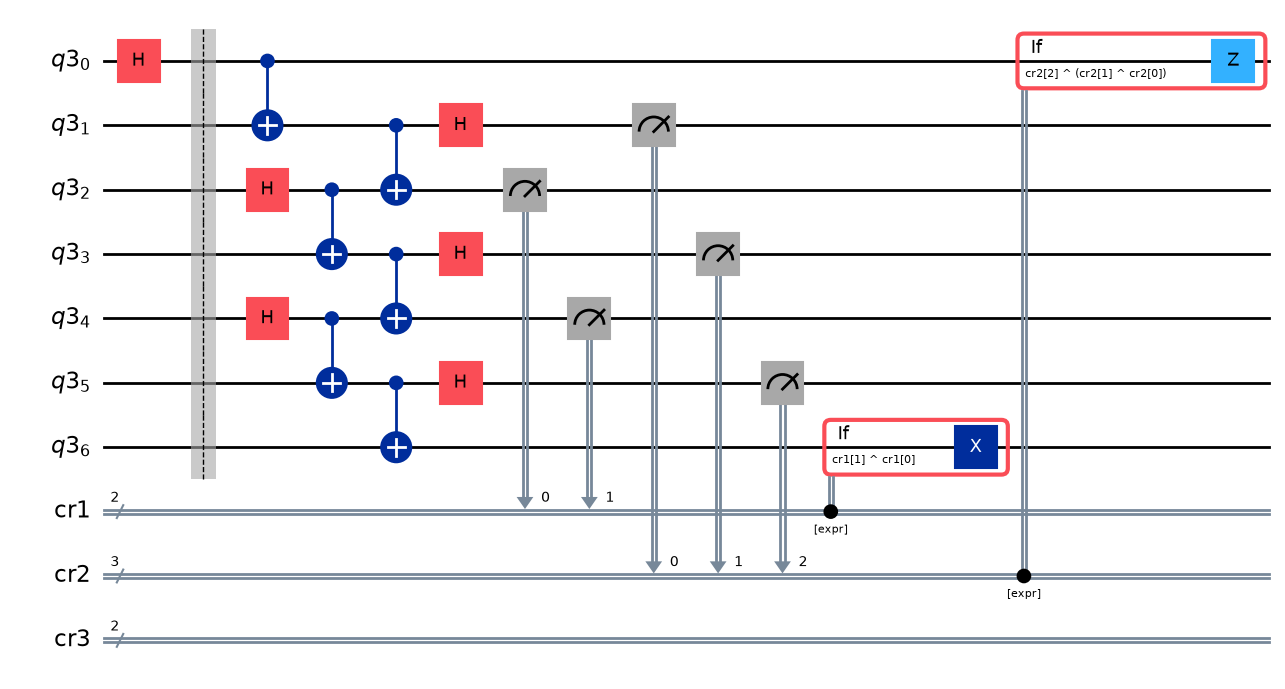

In [13]:
qc = get_dynamic_CNOT_circuit(num_qubit=7)
qc.draw("mpl")

In [14]:
max_num_qubit = 41
qc_list = []

num_qubit_list = list(range(7, max_num_qubit+1, 2))

for num_qubit in num_qubit_list:
    qc_list.append(get_dynamic_CNOT_circuit(num_qubit))



## Step 2 : Optimize the problem for quantum Execution

In [ ]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService


service = QiskitRuntimeService()
for b in service.backends():
    print(b.name)
    print(b.num_qubits)
backend_name = ''
backend = service.backend(backend_name)

pm = generate_preset_pass_manager(optimization_level=1, backend=backend)

qc_transpiled_list = pm.run(qc_list)



## Step 3 : Execution on the backend

In [ ]:
from qiskit_ibm_runtime import SamplerV2 as Sampler
 
sample = Sampler(backend)

job = sample.run(qc_transpiled_list)

print(job.job_id())


## Step 4 : Post processing and plotting

In [ ]:
import matplotlib.pyplot as plt
from qiskit_ibm_runtime import QiskitRuntimeService

job_id = ''

service = QiskitRuntimeService()
job = service.job(job_id=job_id)

result = job.result()

list_Bell = []
list_other = []

for i in range(0, len(qc_list)):
    data = result[i+1].data
    counts = data.cr3.get_counts()
    total_counts = data.cr3.num_shots

    prob_Bell = (counts['00'] + counts['11']) / total_counts

    list_Bell.append(prob_Bell)
    list_other.append(1-prob_Bell)



plt.plot(num_qubit_list, list_Bell, '--o', label='00 or 11')

plt.plot(num_qubit_list, list_other, '-.^', label='other')

plt.xlabel('Number of qubits')
plt.ylabel("Probability")
plt.legend()